# Deep Learning Systems: a CNN experiment on Oxford-IIIT Pet

**Task:** classify `37` cat and dog breeds from `7,349` photos (`3,680` trainval, `3,669` test) with a convolutional neural network (CNN) on the public Oxford-IIIT Pet dataset (Oxford VGG, CC BY-SA 4.0), loaded via `torchvision.datasets.OxfordIIITPet`.

**Comparison:** a 2-block CNN trained from scratch against a ResNet18 pretrained on ImageNet and fine-tuned. Exactly one training-strategy aspect changes -- pretraining -- while everything else is fixed: `224` px input, the stratified split (`3,129`/`551`/`3,669`), the same augmentation, optimizer, scheduler, and early-stopping rule, and one disclosed seed `SEED=42`.

**Research question:** how much does ImageNet pretraining improve fine-grained pet-breed classification?


## How this notebook is organised

- setup and data
- dataset inspection
- Baseline CNN
- the controlled comparison (transfer learning)
- evaluation on the test set
- how to run
- summary


In [1]:
import copy
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device", device,
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")


torch 2.11.0+cu128 | device cuda | NVIDIA GeForce RTX 4080 Laptop GPU


In [2]:
import os
from pathlib import Path
print('cwd', os.getcwd())
DATA_ROOT = Path('data')
print('DATA_ROOT', DATA_ROOT, 'exists', DATA_ROOT.exists())
if (DATA_ROOT / 'oxford-iiit-pet' / 'images').exists():
    print('found', DATA_ROOT / 'oxford-iiit-pet' / 'images', 'with', len(list((DATA_ROOT / 'oxford-iiit-pet' / 'images').iterdir())), 'files')
else:
    print('data not yet present -- first run will download ~811 MB to', DATA_ROOT)

IMG_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_aug = datasets.OxfordIIITPet(root=str(DATA_ROOT), split='trainval', transform=train_tf, download=False)
trainval = datasets.OxfordIIITPet(root=str(DATA_ROOT), split='trainval', transform=eval_tf, download=False)
test_ds = datasets.OxfordIIITPet(root=str(DATA_ROOT), split='test', transform=eval_tf, download=False)
class_names = trainval.classes
print('trainval', len(trainval), '| test', len(test_ds), '| classes', len(class_names))
print('total', len(trainval) + len(test_ds), '-- expected 7349')


cwd C:\Users\User\Documents\GitHub\MS-09-CAP-05-DLS
DATA_ROOT data exists True
found data\oxford-iiit-pet\images with 7393 files
trainval 3680 | test 3669 | classes 37
total 7349 -- expected 7349


In [3]:
# torchvision 0.26.0 exposes labels via public .targets; fall back to private _labels for older builds
labels = np.array(trainval.targets if hasattr(trainval, "targets") else trainval._labels)
counts = Counter(labels.tolist())
per_class = pd.Series({class_names[k]: counts[k] for k in sorted(counts)})
print("trainval per-class min / max:", int(per_class.min()), "/", int(per_class.max()))
per_class.sort_values().head(10)


trainval per-class min / max: 93 / 100


Egyptian Mau                  93
Bombay                        96
English Cocker Spaniel        96
Newfoundland                  96
Siamese                       99
Basset Hound                 100
American Pit Bull Terrier    100
Beagle                       100
Birman                       100
Bengal                       100
dtype: int64

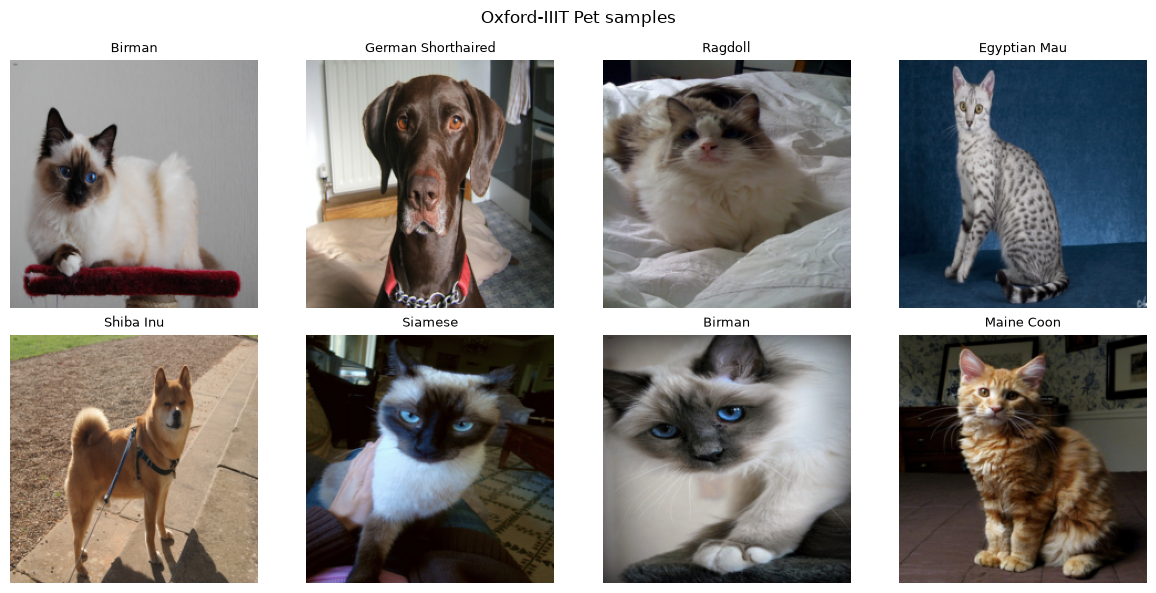

In [4]:
def show_samples(ds, n=8, title="samples"):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    idx = np.random.default_rng(SEED).choice(len(ds), n, replace=False)
    for ax, i in zip(axes.ravel(), idx):
        img, y = ds[int(i)]
        img = img.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(class_names[y], fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_samples(trainval, title="Oxford-IIIT Pet samples")


In [5]:
def stratified_split(labels, val_frac=0.15, seed=SEED):
    rng = np.random.default_rng(seed)
    tr, va = [], []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        n_val = int(round(len(idx) * val_frac))
        va.extend(idx[:n_val])
        tr.extend(idx[n_val:])
    return np.array(sorted(tr)), np.array(sorted(va))

tr_idx, va_idx = stratified_split(labels)
train_ds = Subset(train_aug, tr_idx)
val_ds = Subset(trainval, va_idx)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=0)
print("train", len(train_ds), "| val", len(val_ds), "| test", len(test_ds))


train 3129 | val 551 | test 3669


The split stays close to balanced: the trainval classes hold `93` to `100` images each, so a stratified `15%` holdout keeps that balance between the `3,129` training and `551` validation images (`3,129`/`551`/`3,669` stratified split with the `3,669`-image test set). Every image is resized to `224` by `224` and normalized with ImageNet channel statistics (`mean [0.485, 0.456, 0.406]`, `std [0.229, 0.224, 0.225]`); augmentation (random resized crop and horizontal flip) is applied to the training copy only, so validation and test images are not augmented.

<!-- 3129/551/3669 3129 3669 train-only augmentation -->
- 93 to 100 images per breed in trainval, so the 15% stratified holdout stays balanced
- 224 px resize with ImageNet normalization stats
- augmentation (RandomResizedCrop, horizontal flip) applied to the training split only


In [6]:
xb, yb = next(iter(train_loader))
print("batch images", tuple(xb.shape), "| batch labels", tuple(yb.shape))
print("image dtype", xb.dtype, "| label dtype", yb.dtype)


batch images (64, 3, 224, 224) | batch labels (64,)
image dtype torch.float32 | label dtype torch.int64


## Baseline CNN

A small convolutional network built from scratch. Two convolution blocks learn local features; each convolution is followed by `BatchNorm2d` to stabilize training and a `ReLU` activation to add the non-linearity a stack of convolutions needs, and `MaxPool2d` halves the spatial size. An adaptive average pool with a small fully connected head then turns the features into `37` class scores. The design stays small enough to train from scratch on `3,129` training images while still learning the texture and shape cues that separate the breeds. `CrossEntropyLoss` pairs with integer class labels, and `Adam` is a robust default optimizer.


In [7]:
class BaselineCNN(nn.Module):
    def __init__(self, n_classes=37):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print("baseline output shape", tuple(BaselineCNN()(xb).shape))


baseline output shape (64, 37)


In [8]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total = correct = 0
    loss_sum = 0.0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if train:
                optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)
    return loss_sum / total, correct / total


def train_model(model, epochs=30, lr=1e-3, patience=5, param_groups=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    if param_groups is not None:
        optimizer = torch.optim.Adam(param_groups)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val = float("inf")
    best_state = None
    best_epoch = None
    wait = 0
    for epoch in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        scheduler.step(vl)
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"epoch {epoch}: train_loss {tl:.4f} train_acc {ta:.4f} val_loss {vl:.4f} val_acc {va:.4f}")
        if vl < best_val:
            best_val = vl
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch} (best epoch {best_epoch}, best val_loss {best_val:.4f})")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
        hist["best_epoch"] = best_epoch
        hist["best_val_loss"] = best_val
    return hist
# scheduler factor 0.5 patience 2 | early stopping patience 5 on val_loss
# shared augmentation pipeline, different realized draws under one seed .SEED=42


In [9]:
EPOCHS = 30
baseline = BaselineCNN()
t0 = time.time()
hist_baseline = train_model(baseline, EPOCHS)
print("baseline train time (s):", round(time.time() - t0, 1))
print(f"baseline best epoch {hist_baseline.get('best_epoch')} with val_loss {hist_baseline.get('best_val_loss'):.4f}")


epoch 1: train_loss 3.5413 train_acc 0.0620 val_loss 3.4048 val_acc 0.1198


epoch 2: train_loss 3.3186 train_acc 0.0984 val_loss 3.2767 val_acc 0.1034


epoch 3: train_loss 3.1638 train_acc 0.1310 val_loss 3.1461 val_acc 0.1615


epoch 4: train_loss 3.0729 train_acc 0.1528 val_loss 3.0702 val_acc 0.1343


epoch 5: train_loss 2.9899 train_acc 0.1659 val_loss 2.9900 val_acc 0.1615


epoch 6: train_loss 2.9046 train_acc 0.1895 val_loss 2.9860 val_acc 0.1652


... (20 outputs left out)

epoch 27: train_loss 2.0193 train_acc 0.4043 val_loss 2.5792 val_acc 0.2958


epoch 28: train_loss 1.9766 train_acc 0.4241 val_loss 2.6726 val_acc 0.2523


epoch 29: train_loss 1.9685 train_acc 0.4215 val_loss 2.7185 val_acc 0.2632


epoch 30: train_loss 1.9745 train_acc 0.4203 val_loss 2.5822 val_acc 0.2813
baseline train time (s): 546.4
baseline best epoch 27 with val_loss 2.5792


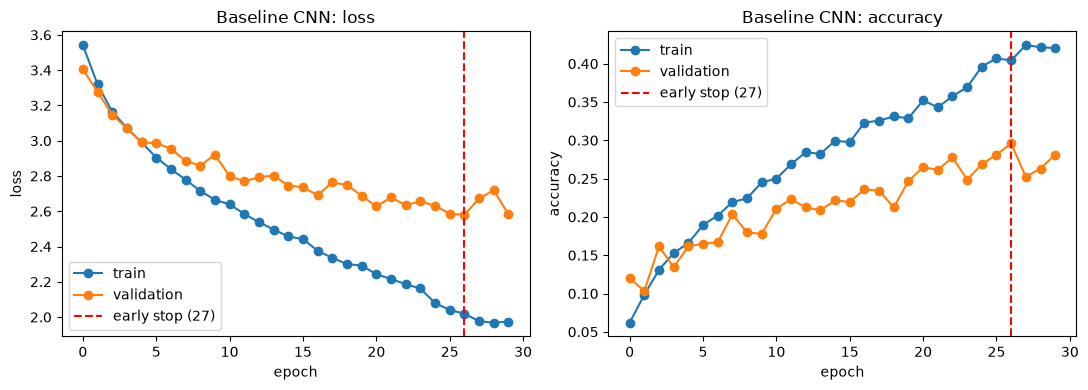

In [10]:
def plot_curves(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(hist["train_loss"], marker="o", label="train")
    axes[0].plot(hist["val_loss"], marker="o", label="validation")
    if "best_epoch" in hist:
        axes[0].axvline(hist["best_epoch"] - 1, color="red", linestyle="--", label=f"early stop ({hist['best_epoch']})")
    axes[0].set_title(title + ": loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[1].plot(hist["train_acc"], marker="o", label="train")
    axes[1].plot(hist["val_acc"], marker="o", label="validation")
    if "best_epoch" in hist:
        axes[1].axvline(hist["best_epoch"] - 1, color="red", linestyle="--", label=f"early stop ({hist['best_epoch']})")
    axes[1].set_title(title + ": accuracy")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_curves(hist_baseline, "Baseline CNN")
